## Datos

* Se presentan en forma de matriz
* Fila: unidad experimental, observación, registro
* Columna: variables

## Estudios

* **OBSERVACIONALES**
    * Surgen como resultado de un proceso de observación, el investigador **observa** y **recoge datos** sin intervenir directamente en el proceso que está estudiando
    * Objetivo: describir y resumir características más sobresalientes
    * Esto se conoce como estadística descriptiva y se basa en el uso de tablas y gráficos, y en la obtención de medidas resumen
    * **No hay intervención del investigador**
    * **NO se manipulan variables**
    * **Ejemplo**: observar si una persona que consumen mas frutas tienen menor incidencia de enfermedades cardiovasculares
* **EXPERIMENTALES**
    * Son el resultado de la provocación de un fenómeno o experimento, bajo condiciones controladas
    * Es un tipo de investigación en el que el investigador interviene activamente en el proceso qye está estudiando
    * Objetivo: **establecer relaciones causales entre variables**, es decir, demostrar que una variable (por ejemplo, un tratamiento) causa un efecto en otra (por ejemplo, una mejora en la salud)
    * **Hay intervención del investigador**
    * **Asignación aleatoria**
    * **Permiten establecer causalidad**
    * **Ejemplo**: dar un suplemento nutricional a un grupo y comparar los resultados con otro grupo que no lo recibe

## Preparación de datos

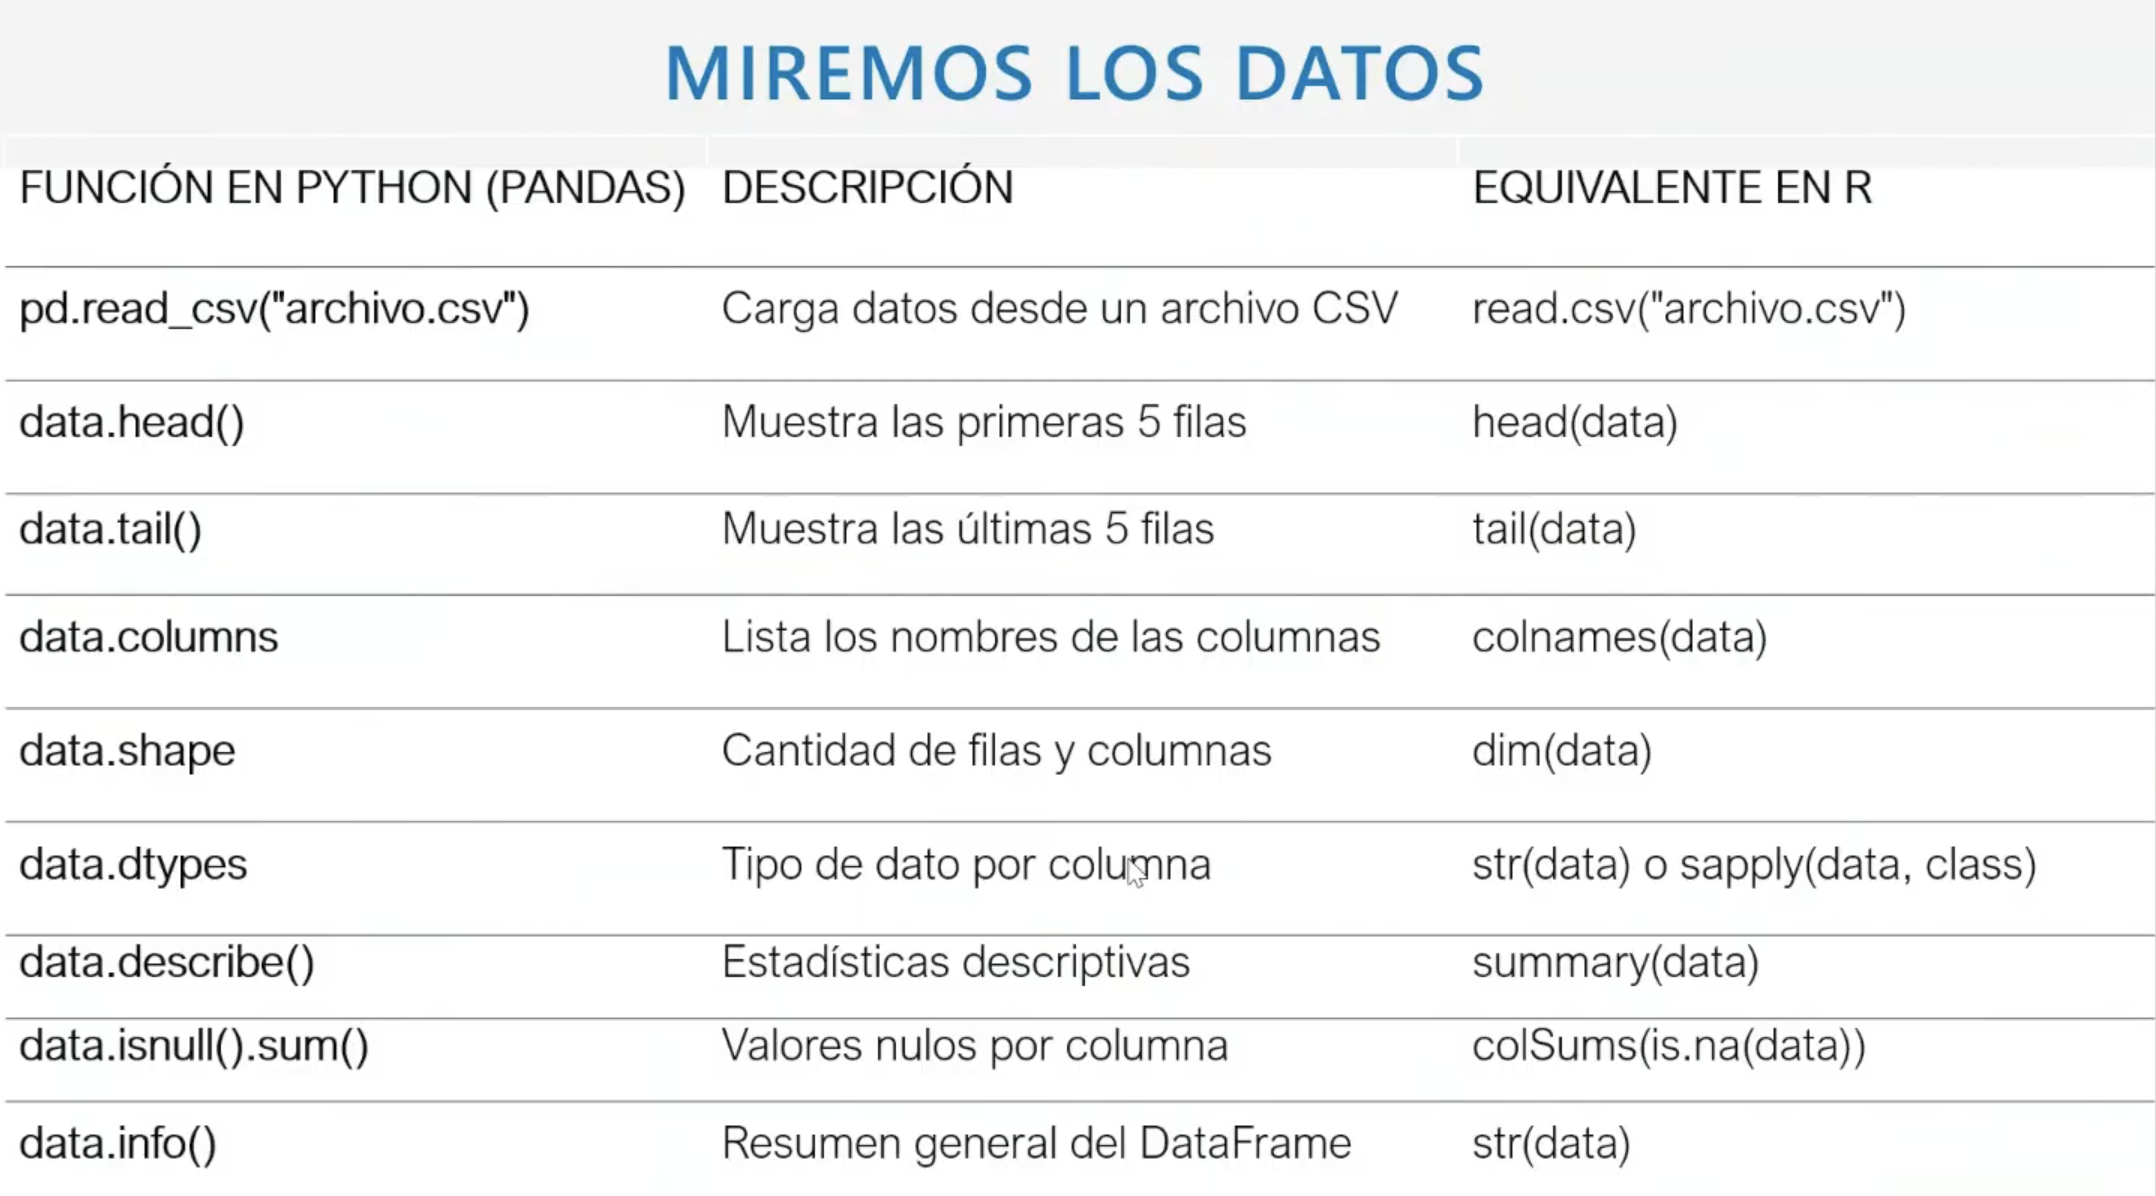

1. Datos faltantes
2. Columnas irrelevantes
3. Registros repetidos (filas)
4. Valores extremos (outliers)
5. Errores tipográficos, en el caso de variables categóricas
6. Datos censurados

### 1. Datos faltantes

* En python:
    * data.info(): sirve para detectar rápidamente si hay datos faltantes y que tipo de datos hay en cada columna
    * data.dropna(inplace=True): elimina todas las filas que contengan al menos un valor faltante
* En R:
    * str(data) y summary(data) 
    * data <- na.omit(data)

**Mecanismos detrás de esa pérdida de datos**
* **MCAR**: Missing Completely At Random
* **MAR**: Missing At Random
* **MNAR**: Missing Not At Random

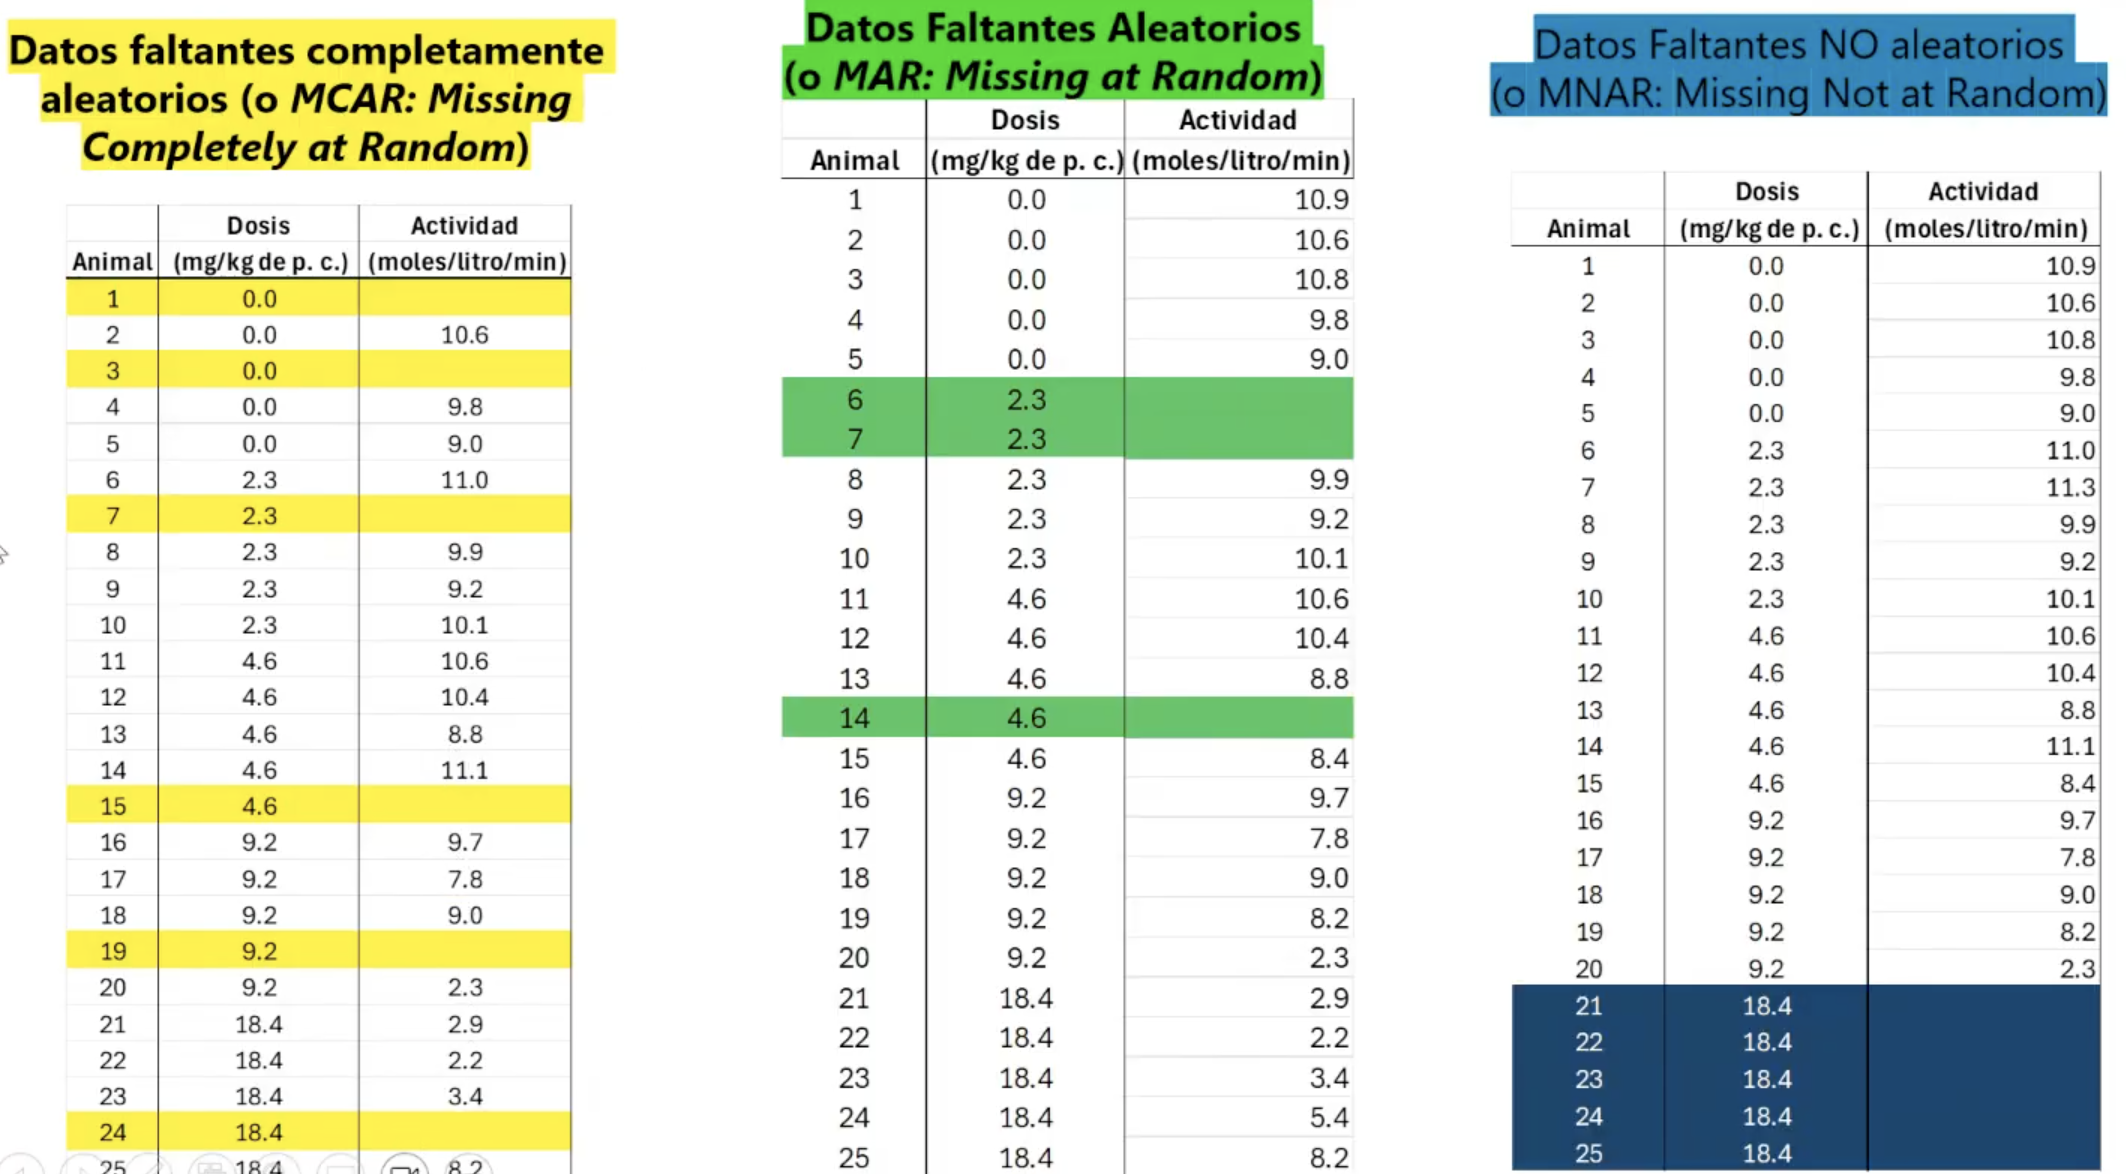

**¿Cómo manejar los datos faltantes?**
* **Descarte**: eliminación de los registros que contengan datos faltantes
    * **listwise deletion**: se elimina la fila completa
    * **pirwise deletion**: se elimina la casilla con el dato faltante 
* **Imputación**: estimación del valor del dato faltante usando la información de los registros vecinos o la información presente en otras variables (o columnas) del set de datos
    * **simple**: media o mediana, valor predicho por un modelo de regresión, hot-deck (promedio de los k vecinos más cercanos)
    * **múltiple**: mice (imputación múltiple con ecuaciones encadenadas)

### 2. Columnas irrelevantes

* No aportan información útil para el análisis o modelo
1. No tienen relación con la variable objetivo
2. Tienen valores constantes o casi constantes (ejemplo: pais = Argentina en todos los casos)
3. Son identificadores únicos (ejemplo: ID_cliente, nro_factura, etc.)
4. Tienen demasiados valores faltantes (ejemplo: columnas con más del 90% de valores nulos)
5. Generan ruidos o confusión en el modelo, afectando su rendimiento

**¿Por qué eliminarlas?**
* Mejoran la **eficiencia computacional**
* Reducen el **riesgo de sobreajuste**
* Facilitan la **interpretación del modelo**
* Se busca un **modelo parsimonioso**, cuanto más simple, mejor!

```
cols_cat = ['nombre1', 'nombre2', 'nombre3']
for col in cols_cat:
    print(f'Columna {col}: {data[col].nunique()} subniveles')
data.describe()
```

### 3. Registros repetidos

* Eliminarlas

```
# Elimina duplicados considerando todas las columnas
data_clean = data.drop_duplicates()
# Elimina duplicados solo considerando la columna 'nombre'
data_clean = data.drop_duplicates(subset='nombre')
# Elimina duplicados y conserva solo la última aparición
data_clean = data.drop_duplicates(keep='last')
# Elimina duplicados directamente en el Dataframe original
data.drop_duplicates(inplace=True)
```

### 4. Valores extremos (outliers)

* Es una observación que se **aleja significativamente del resto de los datos**
* Puede indicar una variabilidad inusual, un error de medición, o una característica interesante del fenómeno que se estudia
* **Regla de oro**: nunca descartar sin investigar primero

**¿Qué factores dan origen a este tipo de valores?**
* Errores en la captura de los datos (error humano o dispositivo)
* El dato observado es un valor extremo

**Técnicas para detección y manejo**
* Visualización: generar una gráfica del set de datos y detectar posteriormente los outiers por simple inspección visual
* Uso de la desviación estándar
* Uso de rangos intercuartiles

**Tratamiento**
* Verificación y corrección:
    * Volver a muestrear o repetir el análisis
    * Corregir errores si se detectan
* Eliminación justificada:
    * Solo si hay una justificación estadística y/o práctica
    * Nunca basarse únicamente en una prueba estadística
* Conservación:
    * Usar métodos estadísticos **robustos** (mediana, rango intercuartílico, regresión robusta, etc.)

**¿Cómo manejar los outliers?**
* Método de eliminación (trimming): se elimina el valor extremo de nuestro set de datos
* Método de recorte (capping): cambiar el valor de los outliers a los límites inferior y superior
* Probar con y sin valores extremos
* NO hacer nada

**Herramientas estadísticas para detectar outliers**
* Muestras pequeñas
    * Prueba de Grubbs
    * Prueba de Dixon
    * Prueba de Rosner
* Muestras grandes (n > 30) o datos no normales
    * Métodos gráficos (boxplots, scatterplots, histograma)
        * boxplot: medidas resumen: n, media, DE, min, max, mediana = Q2, Q1, Q3
        * RI = Q3 -Q1
        * Valor del Bigote Superior teórico (VBST) = Q3 + 1.5RI
        * Me fijo cual es el valor más cercano a VBST en mi muestra, por ejemplo: s => [Q3, s]
        * Valor del Bigote Inferior teórico (VBIT) = Q1 - 1.5RI
        * Me fijo cual es el valor más cercano a VBIT en mi muestra, por ejemplo: i => [i, Q1]
        * Si la media = mediana  => simetria
        * Si la media != mediana => asimetría
    * Z-scores, rango intercuartílico (IQR o RI), transformaciones

**Prueba Z**
* Cálculo del estadístico $z_i = \dfrac{x_i - \bar x_i}{s}$
* El punto de datos se rechaza si z > 3
* La media como la desviación estándar se ven afectadas por la presencia de valores atípicos
* La prueba Z requiere que el conjunto de datos siga una distribución normal

**Conclusiones sobre outliers**
* Los outliers **pueden ser ruido o información valiosa**
* La decisión sobre cómo tratarlos **debe estar fundamentada**
* Es clave considerar tanto el contexto como las herramientas estadísticas
* "Los outliers no siempre son errores... A veces son la clave para descubrir algo importante"

### 5. Errores tipográficos

* Proceso artesanal
* Revisar las categorías: cambiar tipo de letra y unificar

### 6. Datos censurados

* Son valores con una cantidad conocida menor que un umbral
* Ejemplo: "<1.0 mg/L" significa que el valor está por debajo del límite de cuantificación
* Tienen relevancia en estudios ambientales (contaminación en agua, aire, suelos)
* Problema: no pueden analizarse directamente con métodos estadísticos comunes
* Que se hace con esos valores? Se recurren a las normas, que prohiben la eliminación

**Conclusiones sobre datos censurados**
* No deben ignorarse ni tratarse arbitrariamente
* El tratamiento correcto depende del porcentaje de censura
* Métodos avanzados existen, pero requieren formación estadística
* La interpretación debe ser cuidadosa, especialmente si hay decisiones regulatorias